# Random Forest Behavioral Fraud Risk Assessment



In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, confusion_matrix, roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize


## Load Data


In [26]:
train_file = "behavior_fraud_train_featured.csv"
test_file = "behavior_fraud_test_featured.csv"

train = pd.read_csv(train_file)
test = pd.read_csv(test_file)

print("Training data:", train.shape)
print("Testing data :", test.shape)
display(train.head())


Training data: (440000, 72)
Testing data : (110000, 72)


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,customer_median_amount_prior,usual_channel_prior,rare_channel,usual_state_prior,rare_location,location_change,channel_change,high_velocity,behavioral_flag_count,engineered_anomaly_score_0_100
0,TXN000000222,CUST007401,2019-01-01,00:01,Savings,POS,1159.22,Debit,17938.69,Food & Dining,...,1159.22,Mobile_App,0,Telangana,0,0,0,0,2,-7.0
1,TXN000000037,CUST008793,2019-01-01,00:02,NRI,IMPS,2195.36,Credit,82828.47,Education,...,2195.36,Mobile_App,0,Tamil Nadu,0,0,0,0,1,12.5
2,TXN000000142,CUST023777,2019-01-01,00:08,Savings,POS,1550.20,Debit,192356.44,Travel,...,1550.20,ATM,0,Delhi,0,0,0,0,2,-7.0
3,TXN000000067,CUST024301,2019-01-01,00:10,Salary,UPI,1840.52,Credit,96536.64,Utilities,...,1840.52,Mobile_App,0,Gujarat,0,0,0,0,1,12.5
4,TXN000000244,CUST077506,2019-01-01,00:16,Savings,NEFT,54580.63,Debit,11246.28,Salary,...,54580.63,ATM,0,Delhi,0,0,0,0,3,5.5


## Prepare Risk Labels


In [27]:
risk_map = {
    "Low": "Low Risk", "Moderate": "Moderate Risk",
    "High": "High Risk", "Critical": "Critical Risk",
    "Low Risk": "Low Risk", "Moderate Risk": "Moderate Risk",
    "High Risk": "High Risk", "Critical Risk": "Critical Risk"
}

train["risk_level"] = train["risk_level"].astype(str).str.strip().replace(risk_map)
test["risk_level"] = test["risk_level"].astype(str).str.strip().replace(risk_map)

risk_order = ["Low Risk", "Moderate Risk", "High Risk", "Critical Risk"]
y_train = train["risk_level"].copy()
y_test = test["risk_level"].copy()

unexpected = set(y_train.unique()).union(y_test.unique()) - set(risk_order)
if unexpected:
    raise ValueError(f"Unexpected risk labels: {sorted(unexpected)}")

display(y_train.value_counts().reindex(risk_order, fill_value=0).to_frame("Count"))


,Count
risk_level,
Low Risk,399645
Moderate Risk,36469
High Risk,2934
Critical Risk,952


## Risk-Class Distribution


,Train,Test
risk_level,,
Low Risk,399645,101128
Moderate Risk,36469,7885
High Risk,2934,801
Critical Risk,952,186


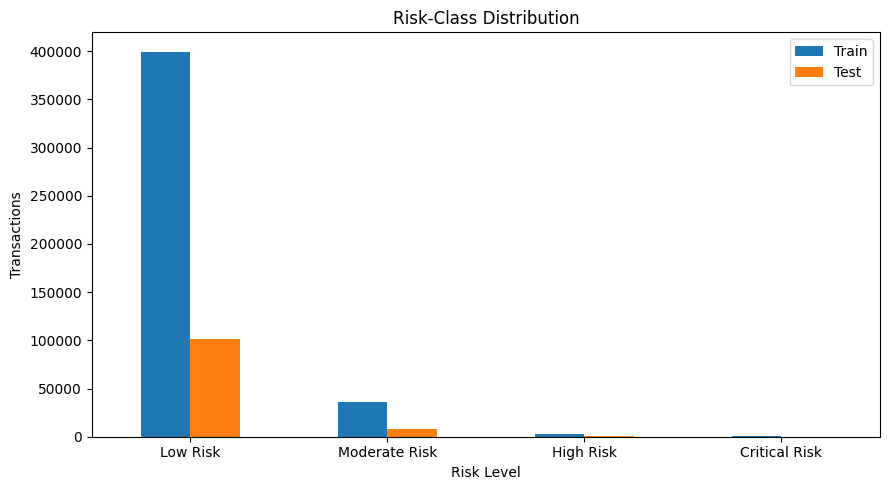

In [28]:
distribution = pd.DataFrame({
    "Train": y_train.value_counts().reindex(risk_order, fill_value=0),
    "Test": y_test.value_counts().reindex(risk_order, fill_value=0)
})
display(distribution)
distribution.plot(kind="bar", figsize=(9,5))
plt.title("Risk-Class Distribution")
plt.xlabel("Risk Level"); plt.ylabel("Transactions"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()


## Behavioral Features


In [29]:
leakage_columns = ["risk_level", "is_fraud", "risk_score", "risk_reasons"]
identifier_columns = ["transaction_id", "customer_id", "account_id", "TransactionID", "CustomerID"]
datetime_columns = ["transaction_date", "transaction_datetime", "transaction_time", "date", "datetime", "timestamp"]
drop_columns = leakage_columns + identifier_columns + datetime_columns

X_train = train.drop(columns=[c for c in drop_columns if c in train.columns], errors="ignore").copy()
X_test = test.drop(columns=[c for c in drop_columns if c in test.columns], errors="ignore").copy()

for col in list(X_train.columns):
    name = col.lower()
    if any(term in name for term in ["date", "time", "datetime", "timestamp"]) and name not in {"transaction_hour", "is_night", "unusual_time"}:
        X_train.drop(columns=col, inplace=True, errors="ignore")
        X_test.drop(columns=col, inplace=True, errors="ignore")

features = [c for c in X_train.columns if c in X_test.columns]
X_train = X_train[features]
X_test = X_test[features]

print("Behavioral features used:", len(features))
display(pd.DataFrame({"Feature": features}))

Behavioral features used: 65


,Feature
0,transaction_time
1,account_type
2,transaction_type
3,transaction_amount
4,transaction_direction
...,...
60,location_change
61,channel_change
62,high_velocity
63,behavioral_flag_count


## Preprocessing


In [30]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool", "str"]).columns.tolist()

numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


## Random Forest Model


In [31]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=16,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen

## Train Model


In [32]:
model.fit(X_train, y_train)
print("Training completed.")


Training completed.


## Predictions


In [33]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

preview = pd.DataFrame({
    "Actual Risk": y_test.reset_index(drop=True),
    "Predicted Risk": pd.Series(y_pred).reset_index(drop=True)
})
display(preview.head(10))


,Actual Risk,Predicted Risk
0,Low Risk,Low Risk
1,Low Risk,Low Risk
2,Low Risk,Low Risk
3,Low Risk,Low Risk
4,Low Risk,Low Risk
5,Low Risk,Low Risk
6,Low Risk,Low Risk
7,Low Risk,Low Risk
8,Low Risk,Low Risk
9,Low Risk,Low Risk


,Actual,Predicted
Low Risk,91.93,100.0
Moderate Risk,7.17,0.0
High Risk,0.73,0.0
Critical Risk,0.17,0.0


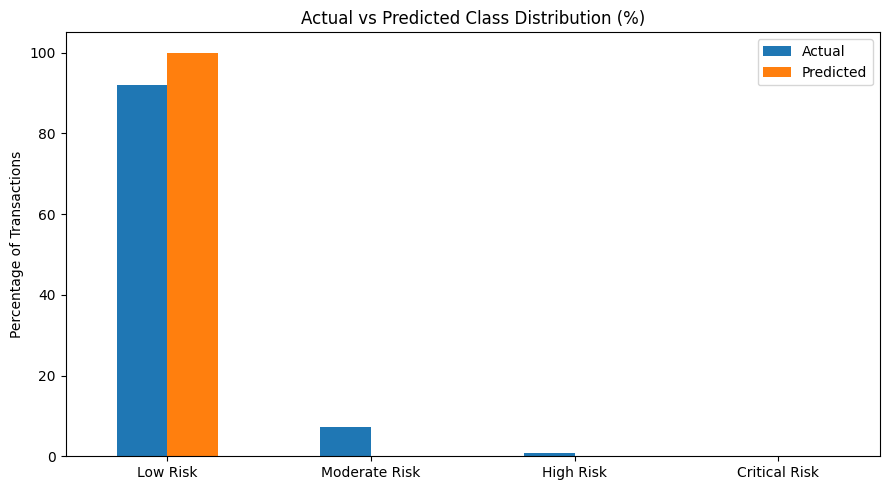

In [34]:
prediction_distribution = pd.DataFrame({
    "Actual": y_test.value_counts(normalize=True).reindex(risk_order, fill_value=0),
    "Predicted": pd.Series(y_pred).value_counts(normalize=True).reindex(risk_order, fill_value=0)
}) * 100

display(prediction_distribution.round(2))
prediction_distribution.plot(kind="bar", figsize=(9,5))
plt.title("Actual vs Predicted Class Distribution (%)")
plt.ylabel("Percentage of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Model Metrics


In [35]:
accuracy = accuracy_score(y_test, y_pred)
rows = [("Accuracy", accuracy)]
for avg in ["macro", "micro", "weighted"]:
    rows.extend([
        (f"{avg.title()} Precision", precision_score(y_test, y_pred, average=avg, zero_division=0)),
        (f"{avg.title()} Recall", recall_score(y_test, y_pred, average=avg, zero_division=0)),
        (f"{avg.title()} F1", f1_score(y_test, y_pred, average=avg, zero_division=0))
    ])

class_order = model.named_steps["classifier"].classes_
y_test_bin = label_binarize(y_test, classes=class_order)
try:
    macro_auc = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")
    weighted_auc = roc_auc_score(y_test_bin, y_proba, average="weighted", multi_class="ovr")
    micro_auc = roc_auc_score(y_test_bin, y_proba, average="micro", multi_class="ovr")
    rows.extend([("Macro ROC-AUC (OvR)", macro_auc), ("Micro ROC-AUC (OvR)", micro_auc), ("Weighted ROC-AUC (OvR)", weighted_auc)])
except ValueError as e:
    print("ROC-AUC could not be calculated:", e)

metrics_df = pd.DataFrame(rows, columns=["Metric", "Score"])
print("Random Forest Model Performance")
display(metrics_df.round(4))
metrics_df.to_csv("random_forest_behavioral_fraud_risk_enhanced_metrics.csv", index=False)


Random Forest Model Performance


,Metric,Score
0,Accuracy,0.9193
1,Macro Precision,0.2298
2,Macro Recall,0.2500
3,Macro F1,0.2395
4,Micro Precision,0.9193
5,Micro Recall,0.9193
6,Micro F1,0.9193
7,Weighted Precision,0.8452
8,Weighted Recall,0.9193
9,Weighted F1,0.8807


## Classification Report


In [36]:
report_df = pd.DataFrame(
    classification_report(
        y_test, y_pred, labels=risk_order,
        output_dict=True, zero_division=0
    )
).T

display(report_df.round(4))
report_df.to_csv("random_forest_classification_report.csv")


,precision,recall,f1-score,support
Low Risk,0.9193,1.0000,0.9580,101128.0000
Moderate Risk,0.0000,0.0000,0.0000,7885.0000
High Risk,0.0000,0.0000,0.0000,801.0000
Critical Risk,0.0000,0.0000,0.0000,186.0000
accuracy,0.9193,0.9193,0.9193,0.9193
macro avg,0.2298,0.2500,0.2395,110000.0000
weighted avg,0.8452,0.9193,0.8807,110000.0000


## Metrics Graph


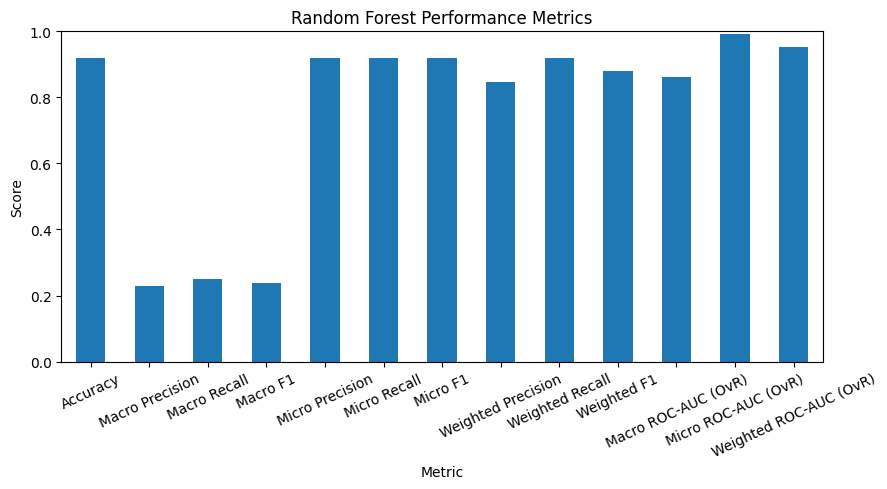

In [37]:
metrics_df.set_index("Metric").plot(kind="bar", legend=False, figsize=(9,5))
plt.title("Random Forest Performance Metrics")
plt.ylabel("Score"); plt.ylim(0,1); plt.xticks(rotation=25)
plt.tight_layout(); plt.show()


## Class-Wise Performance


,precision,recall,f1-score
Low Risk,0.9193,1.0,0.958
Moderate Risk,0.0000,0.0,0.000
High Risk,0.0000,0.0,0.000
Critical Risk,0.0000,0.0,0.000


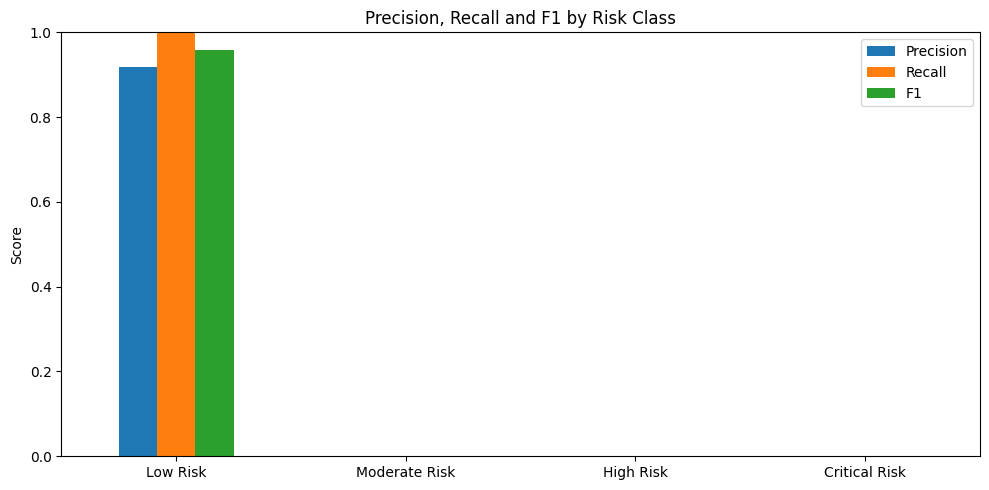

In [38]:
class_metrics = report_df.loc[risk_order, ["precision", "recall", "f1-score"]]
display(class_metrics.round(4))
class_metrics.plot(kind="bar", figsize=(10,5))
plt.title("Precision, Recall and F1 by Risk Class")
plt.ylabel("Score"); plt.ylim(0,1); plt.xticks(rotation=0)
plt.legend(["Precision", "Recall", "F1"])
plt.tight_layout(); plt.show()


## Confusion Matrix


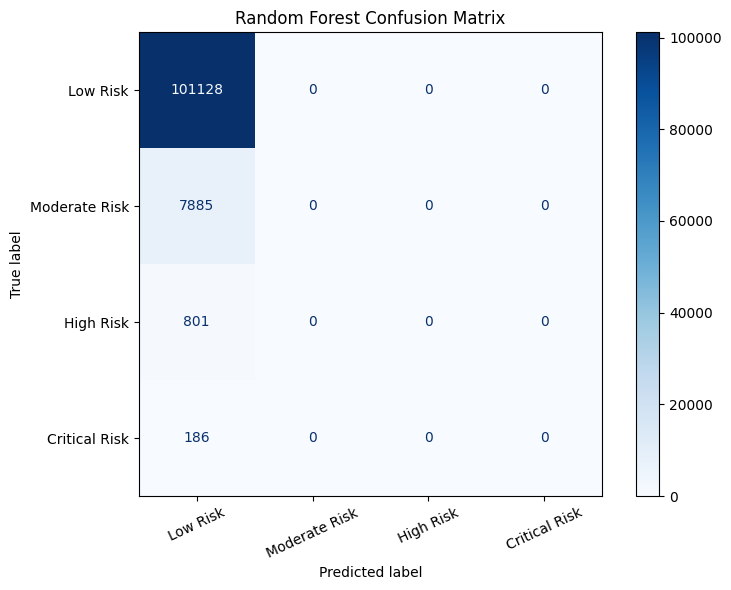

In [39]:
fig, ax = plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=risk_order, display_labels=risk_order,
    cmap="Blues", values_format="d", ax=ax
)
plt.title("Random Forest Confusion Matrix")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()


## Normalized Confusion Matrix


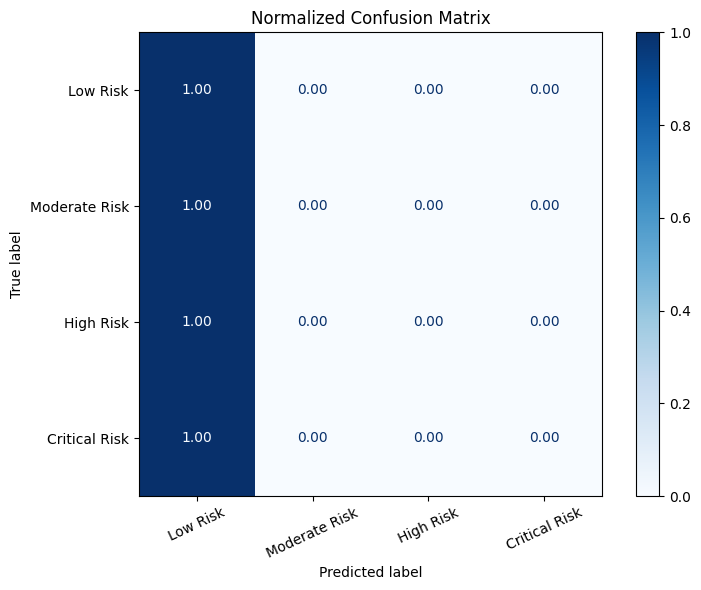

In [40]:
fig, ax = plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=risk_order, display_labels=risk_order,
    normalize="true", cmap="Blues", values_format=".2f", ax=ax
)
plt.title("Normalized Confusion Matrix")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()


## Actual vs Predicted Risk


,Actual,Predicted
Low Risk,101128,110000
Moderate Risk,7885,0
High Risk,801,0
Critical Risk,186,0


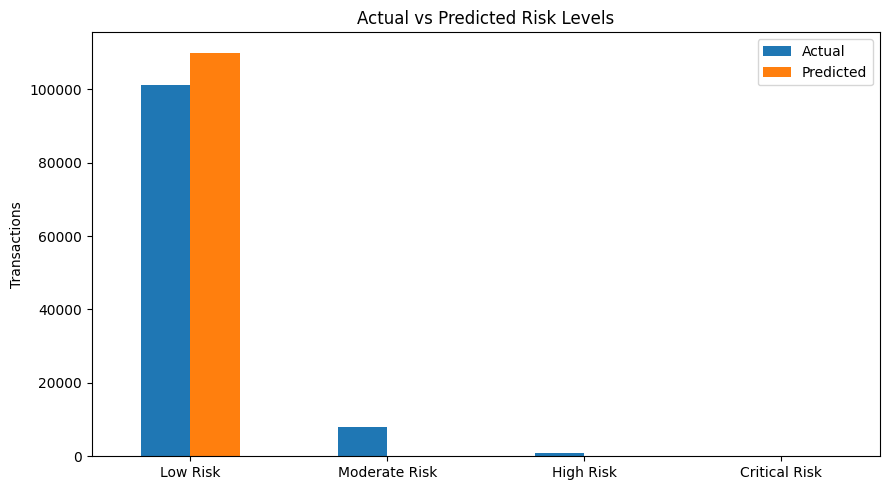

In [41]:
risk_comparison = pd.DataFrame({
    "Actual": y_test.value_counts().reindex(risk_order, fill_value=0),
    "Predicted": pd.Series(y_pred).value_counts().reindex(risk_order, fill_value=0)
})
display(risk_comparison)
risk_comparison.plot(kind="bar", figsize=(9,5))
plt.title("Actual vs Predicted Risk Levels")
plt.ylabel("Transactions"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()


## Probability-Based Predictions


In [42]:
# Align probability columns with the classifier's class order
class_order = model.named_steps["classifier"].classes_
probability_df = pd.DataFrame(
    y_proba,
    columns=[f"P({risk})" for risk in class_order]
)

probability_df["Actual Risk"] = y_test.reset_index(drop=True)
probability_df["Predicted Risk"] = pd.Series(y_pred).reset_index(drop=True)
probability_df["Confidence"] = y_proba.max(axis=1)

display(probability_df.head(15).round(4))
probability_df.to_csv("random_forest_risk_predictions.csv", index=False)


,P(Critical Risk),P(High Risk),P(Low Risk),P(Moderate Risk),Actual Risk,Predicted Risk,Confidence
0,0.0020,0.0068,0.9147,0.0766,Low Risk,Low Risk,0.9147
1,0.0019,0.0068,0.9155,0.0757,Low Risk,Low Risk,0.9155
2,0.0019,0.0068,0.9150,0.0762,Low Risk,Low Risk,0.9150
3,0.0027,0.0067,0.8998,0.0908,Low Risk,Low Risk,0.8998
4,0.0020,0.0067,0.9145,0.0769,Low Risk,Low Risk,0.9145
5,0.0018,0.0069,0.9231,0.0682,Low Risk,Low Risk,0.9231
6,0.0020,0.0067,0.9151,0.0762,Low Risk,Low Risk,0.9151
7,0.0019,0.0068,0.9184,0.0729,Low Risk,Low Risk,0.9184
8,0.0019,0.0069,0.9189,0.0723,Low Risk,Low Risk,0.9189
9,0.0019,0.0068,0.9182,0.0731,Low Risk,Low Risk,0.9182


## Prediction Confidence


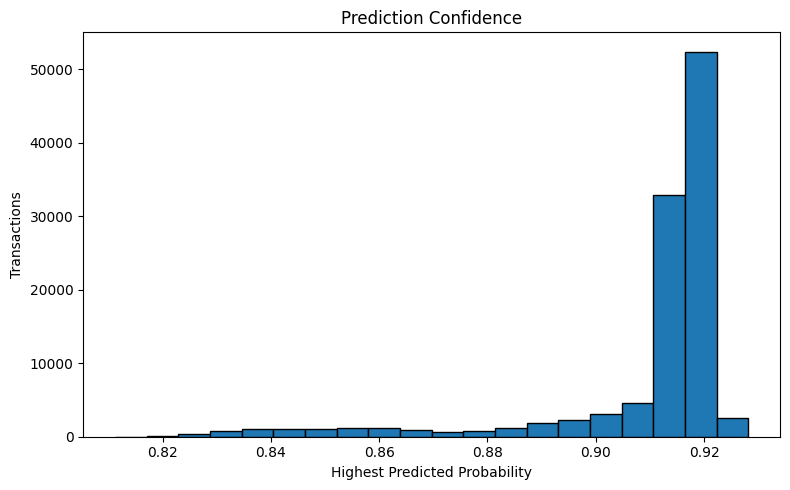

In [43]:
plt.figure(figsize=(8,5))
plt.hist(probability_df["Confidence"], bins=20, edgecolor="black")
plt.title("Prediction Confidence")
plt.xlabel("Highest Predicted Probability"); plt.ylabel("Transactions")
plt.tight_layout(); plt.show()


## Feature Importance


,Feature,Importance
21,numeric__amount_vs_customer_avg,0.0400
1505,categorical__transaction_type_RTGS,0.0400
38,numeric__amount_zscore_behavior,0.0375
37,numeric__amount_ratio_prior,0.0364
22,numeric__amount_zscore_prior,0.0333
36,numeric__amount_deviation_prior,0.0313
50,numeric__behavioral_flag_count,0.0310
35,numeric__log_transaction_amount,0.0306
40,numeric__unusual_time,0.0273
41,numeric__balance_usage_ratio,0.0268


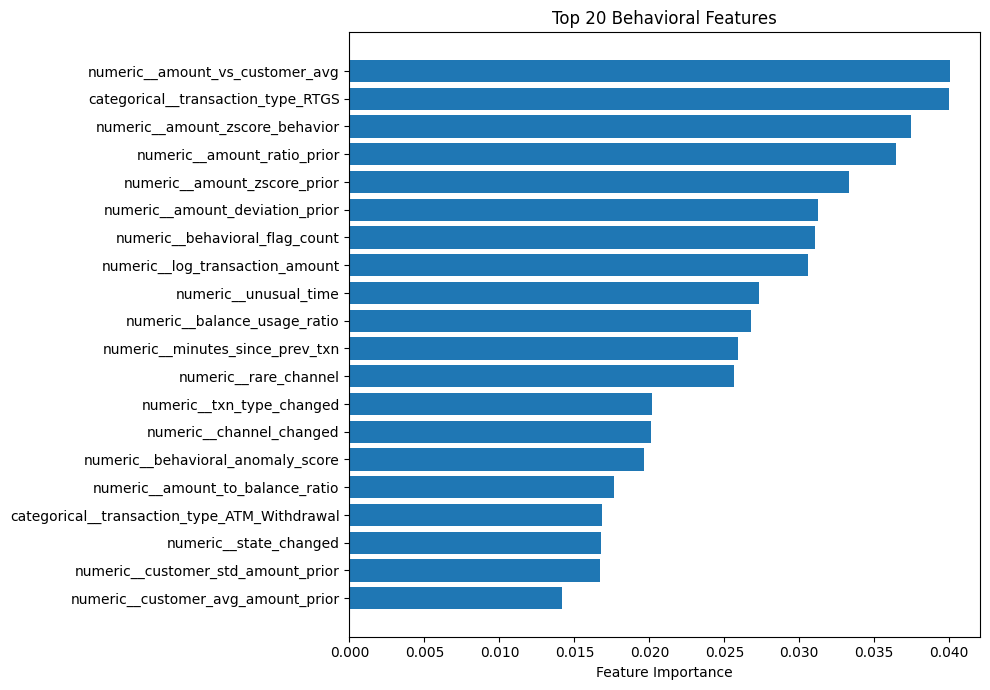

In [44]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importance = model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

top_features = importance_df.head(20)
display(top_features.round(4))

plt.figure(figsize=(10,7))
plt.barh(top_features["Feature"][::-1], top_features["Importance"][::-1])
plt.title("Top 20 Behavioral Features")
plt.xlabel("Feature Importance")
plt.tight_layout(); plt.show()

importance_df.to_csv("random_forest_feature_importance.csv", index=False)


## Metric Comparison
Accuracy and multiclass precision, recall and F1 scores.


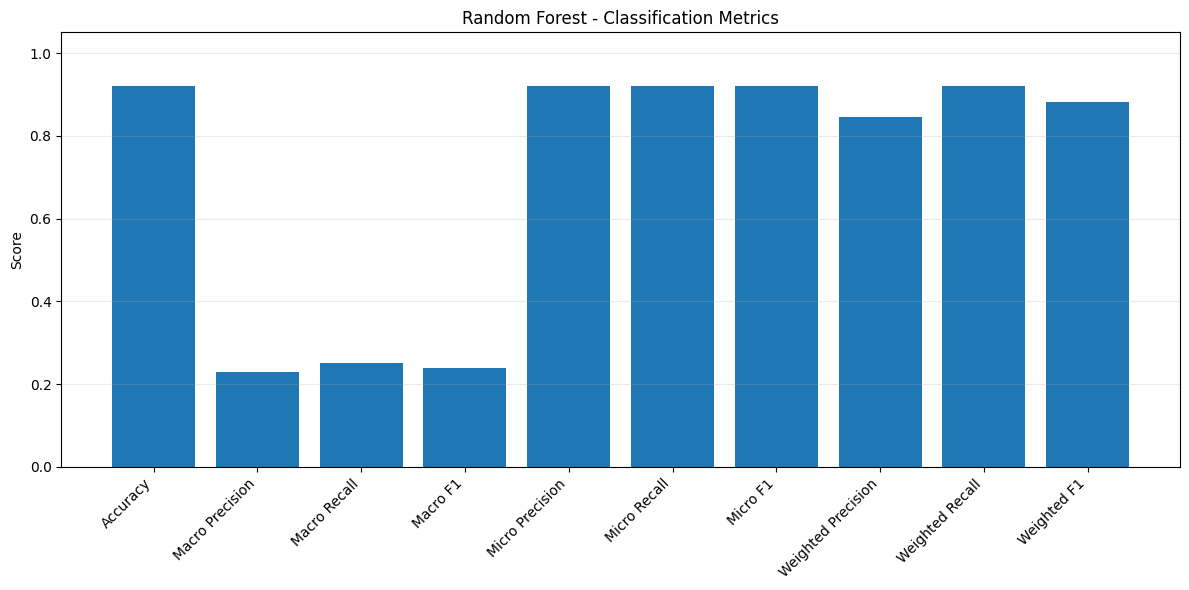

In [45]:
plot_metrics = metrics_df[~metrics_df["Metric"].str.contains("ROC-AUC")].copy()
plt.figure(figsize=(12,6))
plt.bar(plot_metrics["Metric"], plot_metrics["Score"])
plt.ylim(0,1.05)
plt.ylabel("Score")
plt.title("Random Forest - Classification Metrics")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()


## Class-wise Metrics Heatmap
Precision, recall and F1-score for each risk level.


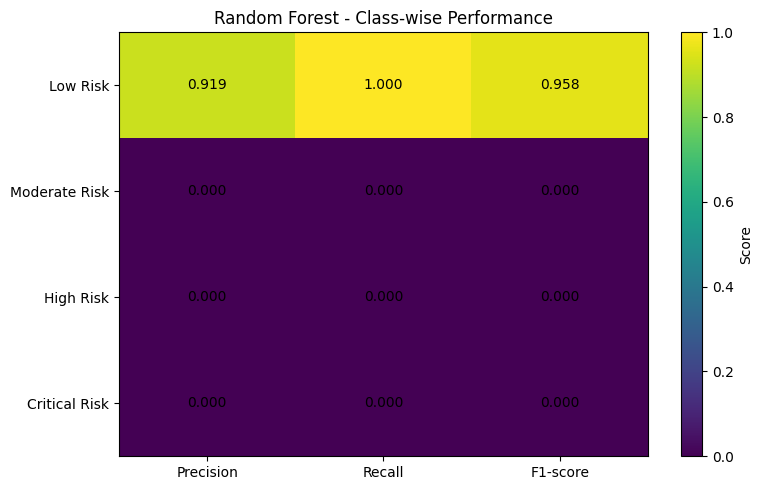

In [46]:
class_perf = report_df.loc[risk_order, ["precision", "recall", "f1-score"]]
fig, ax = plt.subplots(figsize=(8,5))
im = ax.imshow(class_perf.values, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(3), ["Precision", "Recall", "F1-score"])
ax.set_yticks(range(len(risk_order)), risk_order)
for i in range(class_perf.shape[0]):
    for j in range(class_perf.shape[1]):
        ax.text(j, i, f"{class_perf.iloc[i,j]:.3f}", ha="center", va="center")
plt.colorbar(im, ax=ax, label="Score")
plt.title("Random Forest - Class-wise Performance")
plt.tight_layout(); plt.show()


## ROC Curves
One-vs-rest ROC curves for the four risk classes.


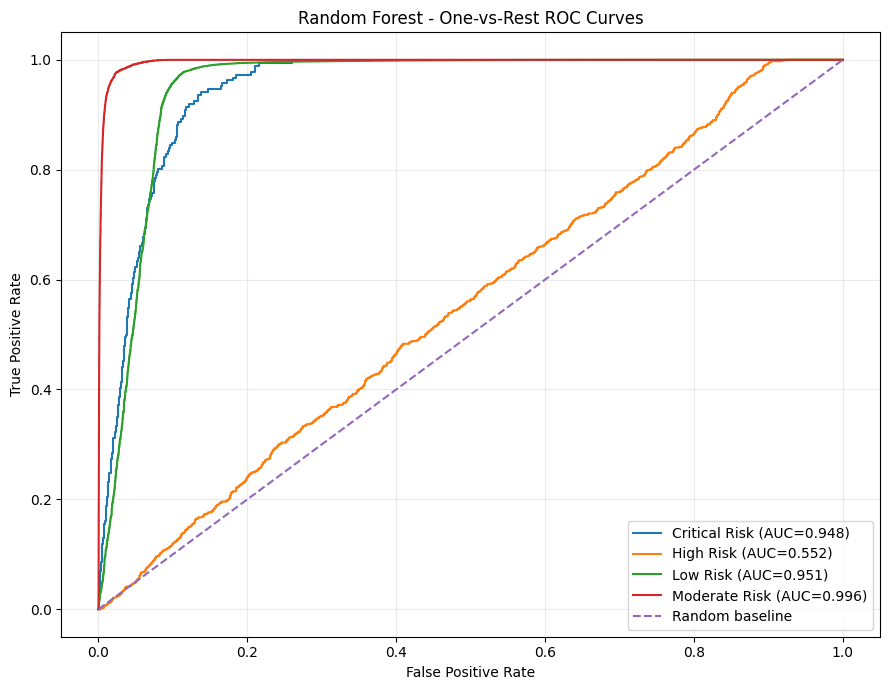

In [47]:
plt.figure(figsize=(9,7))
for i, cls in enumerate(class_order):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{cls} (AUC={class_auc:.3f})")
plt.plot([0,1], [0,1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - One-vs-Rest ROC Curves")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()


## Error Rate by Risk Class


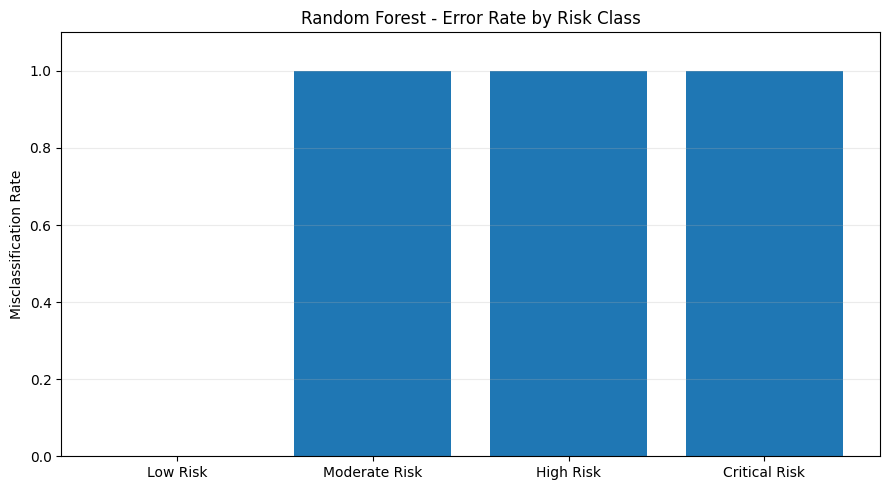

,Error %
Actual,
Low Risk,0.0
Moderate Risk,100.0
High Risk,100.0
Critical Risk,100.0


In [48]:
error_df = pd.DataFrame({"Actual": y_test.reset_index(drop=True), "Predicted": pd.Series(y_pred)})
error_df["Incorrect"] = error_df["Actual"] != error_df["Predicted"]
error_rate = error_df.groupby("Actual")["Incorrect"].mean().reindex(risk_order)
plt.figure(figsize=(9,5))
plt.bar(error_rate.index, error_rate.values)
plt.ylim(0, max(1.0, float(error_rate.max()) * 1.1))
plt.ylabel("Misclassification Rate")
plt.title("Random Forest - Error Rate by Risk Class")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()
display((error_rate * 100).round(2).rename("Error %").to_frame())


## Correct vs Incorrect Predictions by Risk Class


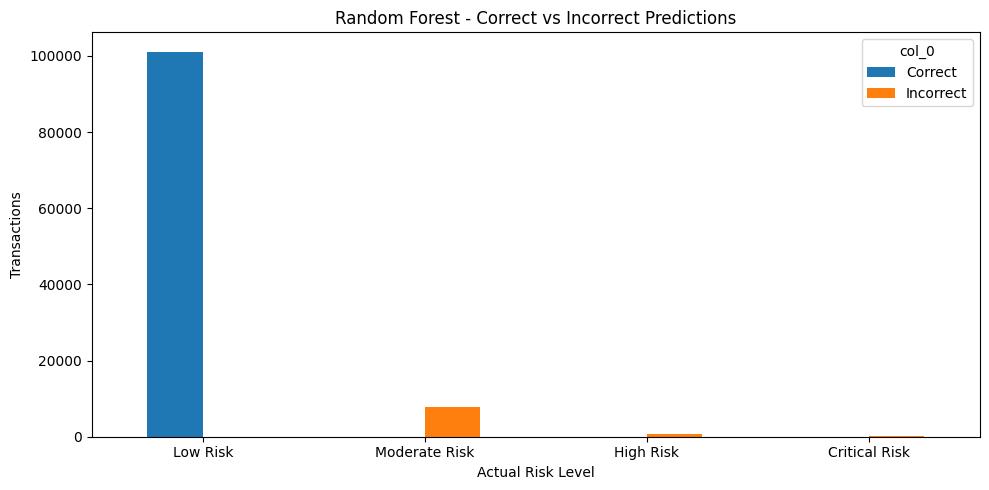

In [49]:
ct = pd.crosstab(error_df["Actual"], np.where(error_df["Incorrect"], "Incorrect", "Correct")).reindex(risk_order, fill_value=0)
ct.plot(kind="bar", figsize=(10,5))
plt.title("Random Forest - Correct vs Incorrect Predictions")
plt.xlabel("Actual Risk Level"); plt.ylabel("Transactions")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()


## Metric Notes
- **Accuracy:** overall correct predictions.
- **Precision:** how often a predicted class is correct.
- **Recall:** how many actual cases of a class are detected.
- **F1-score:** balance between precision and recall.
- **Macro average:** gives every risk class equal importance.
- **Weighted average:** accounts for class frequency.
- **ROC-AUC:** measures how well the model separates each class from the others.

For this multiclass fraud-risk problem, macro F1 and macro recall are useful alongside accuracy because performance on the less frequent high-risk classes should not be hidden by the larger classes.
